# Tox21 Preprocessing (Project 8 - Phase 1)
Pipeline: **load & explore → clean/validate SMILES → scaffold split → plots → save**.

Design decisions
- Unknown labels stay as `NaN` (never 0). They must be **masked**, not imputed, at training/evaluation time.
- Salts/mixtures are reduced to the largest fragment; SMILES are canonicalised before duplicate detection.
- Duplicate molecules are merged; conflicting labels become `NaN`.
- Deterministic Bemis-Murcko scaffold split (80/10/10) so every team member gets the same split.

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.*")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

INPUT = "tox21.csv"          # path to the raw file
OUTDIR = Path("processed")   # everything is saved here
(OUTDIR / "figures").mkdir(parents=True, exist_ok=True)

TASKS = ["NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
         "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
report = {}

## 1. Load and explore

In [2]:
raw = pd.read_csv(INPUT)
assert all(t in raw.columns for t in TASKS)
report["raw_rows"] = len(raw)
print("Shape:", raw.shape)
raw.head()

Shape: (7831, 14)


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


In [3]:
def label_stats(df):
    rows = []
    for t in TASKS:
        a, i = int((df[t] == 1).sum()), int((df[t] == 0).sum())
        rows.append({
            "assay": t, "active": a, "inactive": i, "labelled": a + i,
            "missing": int(df[t].isna().sum()),
            "missing_pct": round(100 * df[t].isna().mean(), 2),
            "active_pct": round(100 * a / (a + i), 2),
            "imbalance (inactive:active)": round(i / a, 1),
        })
    return pd.DataFrame(rows).set_index("assay")

report["raw_duplicate_mol_id"] = int(raw["mol_id"].duplicated().sum())
report["raw_duplicate_smiles_exact"] = int(raw["smiles"].duplicated().sum())
report["raw_missing_smiles"] = int(raw["smiles"].isna().sum())
report["raw_rows_all_labels_missing"] = int(raw[TASKS].isna().all(axis=1).sum())
for k in ["raw_duplicate_mol_id", "raw_duplicate_smiles_exact",
          "raw_missing_smiles", "raw_rows_all_labels_missing"]:
    print(f"{k}: {report[k]}")

raw_stats = label_stats(raw)
raw_stats

raw_duplicate_mol_id: 0
raw_duplicate_smiles_exact: 0
raw_missing_smiles: 0
raw_rows_all_labels_missing: 0


,active,inactive,labelled,missing,missing_pct,active_pct,imbalance (inactive:active)
assay,,,,,,,
NR-AR,309,6956,7265,566,7.23,4.25,22.5
NR-AR-LBD,237,6521,6758,1073,13.70,3.51,27.5
NR-AhR,768,5781,6549,1282,16.37,11.73,7.5
NR-Aromatase,300,5521,5821,2010,25.67,5.15,18.4
NR-ER,793,5400,6193,1638,20.92,12.80,6.8
NR-ER-LBD,350,6605,6955,876,11.19,5.03,18.9
NR-PPAR-gamma,186,6264,6450,1381,17.64,2.88,33.7
SR-ARE,942,4890,5832,1999,25.53,16.15,5.2
SR-ATAD5,264,6808,7072,759,9.69,3.73,25.8


**Observations:** no duplicate IDs / exact-string duplicates, but missing labels are substantial (7-26% per assay) and the classes are heavily imbalanced (~3-16% active).

## 2. Clean and validate SMILES

In [4]:
def largest_fragment(mol):
    frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
    return mol if len(frags) == 1 else max(frags, key=lambda m: m.GetNumHeavyAtoms())

df = raw.copy()

# --- parse ---
df["mol"] = [Chem.MolFromSmiles(s) if isinstance(s, str) and s.strip() else None
             for s in df["smiles"]]
bad = df["mol"].isna() | df["mol"].apply(lambda m: m is not None and m.GetNumAtoms() == 0)
report["invalid_smiles_removed"] = int(bad.sum())
report["invalid_smiles_mol_ids"] = df.loc[bad, "mol_id"].tolist()
print("Invalid SMILES removed:", int(bad.sum()), report["invalid_smiles_mol_ids"])
df = df[~bad].copy()

# --- salts / mixtures -> largest fragment, canonicalise ---
report["multi_fragment_smiles"] = int(df["smiles"].str.contains(r"\.", regex=True).sum())
print("Multi-fragment SMILES reduced to largest fragment:", report["multi_fragment_smiles"])
df["mol"] = df["mol"].apply(largest_fragment)
df["smiles_original"] = df["smiles"]
df["smiles"] = df["mol"].apply(lambda m: Chem.MolToSmiles(m, canonical=True))

# --- rows with no labels at all ---
no_label = df[TASKS].isna().all(axis=1)
report["rows_without_any_label_removed"] = int(no_label.sum())
df = df[~no_label].copy()
print("Rows with no labels removed:", int(no_label.sum()))

Invalid SMILES removed: 8 ['TOX31563', 'TOX24724', 'TOX24723', 'TOX24552', 'TOX24622', 'TOX7518', 'TOX28892', 'TOX28623']
Multi-fragment SMILES reduced to largest fragment: 244


Rows with no labels removed: 0


In [5]:
# --- duplicates (by canonical SMILES) ---
dups = df.groupby("smiles").filter(lambda g: len(g) > 1)
report["duplicate_groups"] = int(dups["smiles"].nunique())
report["duplicate_rows_involved"] = len(dups)
print(f"Duplicate molecules: {report['duplicate_groups']} groups / {len(dups)} rows")

# Merge: agreeing labels kept; conflicting labels -> NaN (never guessed); unknown stays NaN
conflicts, merged = 0, []
for smi, g in df.groupby("smiles", sort=False):
    if len(g) == 1:
        merged.append(g.iloc[0]); continue
    row = g.iloc[0].copy()
    for t in TASKS:
        vals = set(g[t].dropna().unique())
        if len(vals) == 1:
            row[t] = vals.pop()
        else:
            if len(vals) > 1: conflicts += 1
            row[t] = np.nan
    row["mol_id"] = ";".join(g["mol_id"].astype(str))
    merged.append(row)

df = pd.DataFrame(merged).reset_index(drop=True)
df[TASKS] = df[TASKS].astype(float)       # float keeps NaN
report["duplicate_label_conflicts_set_to_nan"] = conflicts
report["clean_rows"] = len(df)
print("Conflicting labels set to NaN:", conflicts)
print("Rows after cleaning:", len(df), "| smiles unique:", df["smiles"].is_unique)

clean_stats = label_stats(df)
report["clean_label_stats"] = clean_stats.reset_index().to_dict(orient="records")
clean_stats

Duplicate molecules: 72 groups / 187 rows


Conflicting labels set to NaN: 47
Rows after cleaning: 7708 | smiles unique: True


,active,inactive,labelled,missing,missing_pct,active_pct,imbalance (inactive:active)
assay,,,,,,,
NR-AR,304,6837,7141,567,7.36,4.26,22.5
NR-AR-LBD,235,6416,6651,1057,13.71,3.53,27.3
NR-AhR,763,5680,6443,1265,16.41,11.84,7.4
NR-Aromatase,286,5430,5716,1992,25.84,5.00,19.0
NR-ER,780,5321,6101,1607,20.85,12.78,6.8
NR-ER-LBD,343,6507,6850,858,11.13,5.01,19.0
NR-PPAR-gamma,185,6168,6353,1355,17.58,2.91,33.3
SR-ARE,915,4821,5736,1972,25.58,15.95,5.3
SR-ATAD5,261,6700,6961,747,9.69,3.75,25.7


## 3. Scaffold split (Bemis-Murcko, 80/10/10)

In [6]:
def murcko_scaffold(mol):
    try:
        return MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
    except Exception:
        return ""

def scaffold_split(df, f_train=0.8, f_val=0.1):
    """Largest scaffold groups first -> train, then val, then test (deterministic)."""
    groups = defaultdict(list)
    for idx, sc in zip(df.index, df["scaffold"]):
        groups[sc].append(idx)
    ordered = sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0]))
    n = len(df); tr_cut, va_cut = f_train * n, (f_train + f_val) * n
    tr, va, te = [], [], []
    for _, idxs in ordered:
        if len(tr) + len(idxs) <= tr_cut:              tr += idxs
        elif len(tr) + len(va) + len(idxs) <= va_cut:  va += idxs
        else:                                          te += idxs
    return sorted(tr), sorted(va), sorted(te)

df["scaffold"] = df["mol"].apply(murcko_scaffold)
df = df.drop(columns=["mol"]).reset_index(drop=True)

tr, va, te = scaffold_split(df)
splits = {"train": tr, "val": va, "test": te}
df["split"] = "train"; df.loc[va, "split"] = "val"; df.loc[te, "split"] = "test"

# leakage checks
sc = {k: set(df.loc[v, "scaffold"]) for k, v in splits.items()}
assert not (sc["train"] & sc["val"] or sc["train"] & sc["test"] or sc["val"] & sc["test"])
assert len(tr) + len(va) + len(te) == len(df)
print("No scaffold shared between train/val/test: OK")

report["n_unique_scaffolds"] = int(df["scaffold"].nunique())
report["acyclic_molecules_empty_scaffold"] = int((df["scaffold"] == "").sum())
report["split_sizes"] = {k: len(v) for k, v in splits.items()}
report["split_active_counts"] = {k: {t: int((df.loc[v, t] == 1).sum()) for t in TASKS} for k, v in splits.items()}
report["split_labelled_counts"] = {k: {t: int(df.loc[v, t].notna().sum()) for t in TASKS} for k, v in splits.items()}
print("Unique scaffolds:", report["n_unique_scaffolds"],
      "| acyclic (empty scaffold):", report["acyclic_molecules_empty_scaffold"])
print("Split sizes:", report["split_sizes"])

# actives / labelled per split & assay
pd.DataFrame({k: {t: f"{report['split_active_counts'][k][t]}/{report['split_labelled_counts'][k][t]}"
                  for t in TASKS} for k in splits}).rename_axis("assay (actives/labelled)")

No scaffold shared between train/val/test: OK
Unique scaffolds: 2285 | acyclic (empty scaffold): 1753
Split sizes: {'train': 6166, 'val': 771, 'test': 771}


,train,val,test
assay (actives/labelled),,,
NR-AR,248/5740,42/710,14/691
NR-AR-LBD,196/5430,27/623,12/598
NR-AhR,579/5235,74/626,110/582
NR-Aromatase,197/4714,36/512,53/490
NR-ER,643/5028,65/536,72/537
NR-ER-LBD,296/5560,23/659,24/631
NR-PPAR-gamma,129/5234,24/560,32/559
SR-ARE,685/4790,110/449,120/497
SR-ATAD5,195/5657,33/659,33/645


> **Note:** acyclic molecules have no ring scaffold, so they form one large group that this standard algorithm assigns entirely to **train**. Validation/test therefore contain only ring-containing molecules. Some test assays also have very few actives (e.g. NR-AR 14, NR-AR-LBD 12), so metrics there will be noisy.

## 4. Visualise

### 4.1 Missing-label percentage per assay

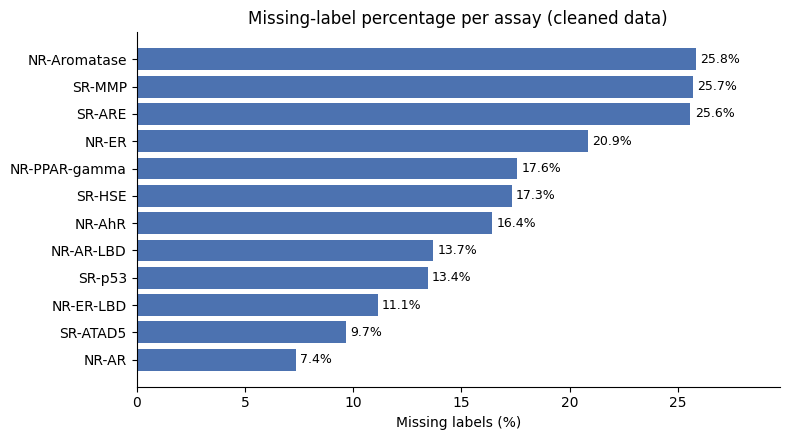

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
s = clean_stats["missing_pct"].sort_values()
ax.barh(s.index, s.values, color="#4C72B0")
for y, v in enumerate(s.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Missing labels (%)"); ax.set_xlim(0, s.max() * 1.15)
ax.set_title("Missing-label percentage per assay (cleaned data)")
fig.tight_layout(); fig.savefig(OUTDIR / "figures/missing_labels.png", dpi=200); plt.show()

### 4.2 Active vs inactive counts (log scale, NaN excluded)

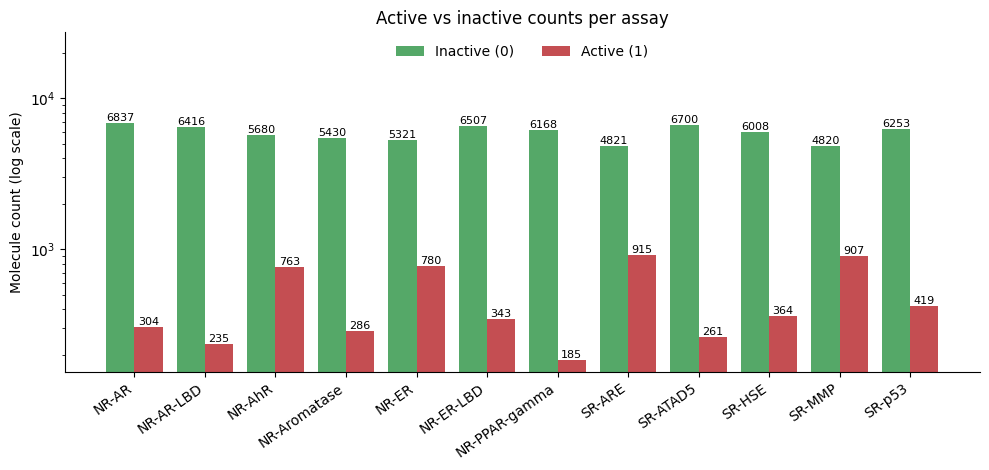

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(clean_stats)); w = 0.4
ax.bar(x - w/2, clean_stats["inactive"], w, label="Inactive (0)", color="#55A868")
ax.bar(x + w/2, clean_stats["active"],   w, label="Active (1)",   color="#C44E52")
for xi, (a, i) in enumerate(zip(clean_stats["active"], clean_stats["inactive"])):
    ax.text(xi + w/2, a, str(a), ha="center", va="bottom", fontsize=8)
    ax.text(xi - w/2, i, str(i), ha="center", va="bottom", fontsize=8)
ax.set_yscale("log"); ax.set_ylim(top=clean_stats["inactive"].max() * 4)
ax.set_xticks(x); ax.set_xticklabels(clean_stats.index, rotation=35, ha="right")
ax.set_ylabel("Molecule count (log scale)")
ax.set_title("Active vs inactive counts per assay")
ax.legend(frameon=False, loc="upper center", ncol=2)
fig.tight_layout(); fig.savefig(OUTDIR / "figures/active_vs_inactive.png", dpi=200); plt.show()

### 4.3 Dataset split sizes

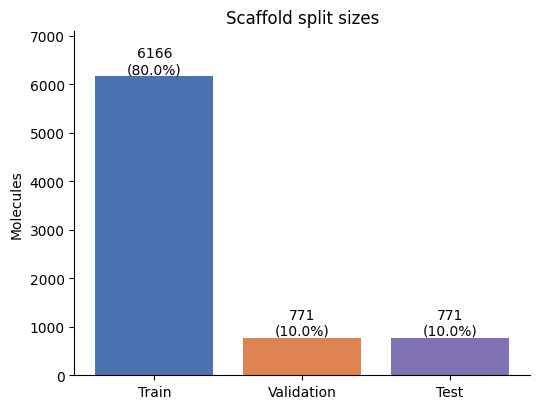

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sizes = [len(tr), len(va), len(te)]
bars = ax.bar(["Train", "Validation", "Test"], sizes, color=["#4C72B0", "#DD8452", "#8172B3"])
for b, sz in zip(bars, sizes):
    ax.text(b.get_x() + b.get_width()/2, sz, f"{sz}\n({100*sz/sum(sizes):.1f}%)", ha="center", va="bottom")
ax.set_ylabel("Molecules"); ax.set_ylim(0, max(sizes) * 1.15)
ax.set_title("Scaffold split sizes")
fig.tight_layout(); fig.savefig(OUTDIR / "figures/split_sizes.png", dpi=200); plt.show()

### 4.4 Positive rate per assay in each split (distribution-shift check)

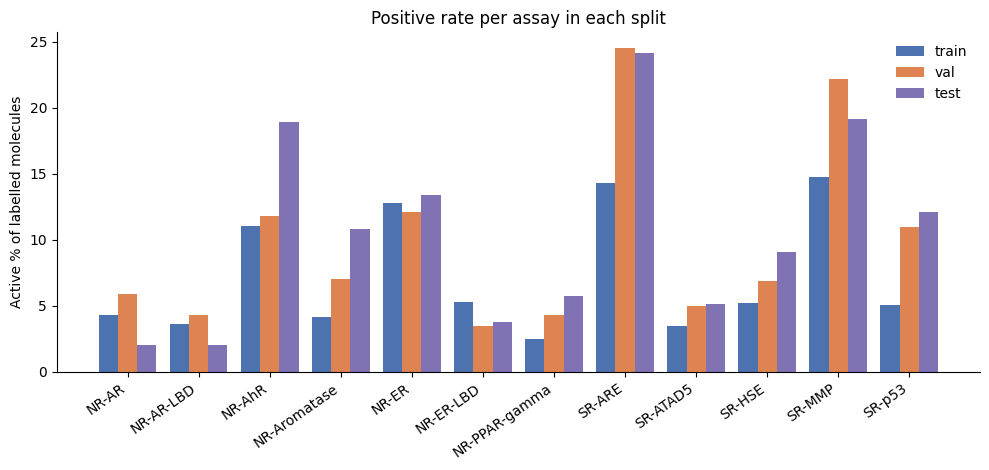

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
w = 0.27
for k, (name, col) in enumerate(zip(["train", "val", "test"], ["#4C72B0", "#DD8452", "#8172B3"])):
    sub = df.loc[splits[name], TASKS]
    ax.bar(x + (k - 1) * w, ((sub == 1).sum() / sub.notna().sum() * 100).values, w, label=name, color=col)
ax.set_xticks(x); ax.set_xticklabels(TASKS, rotation=35, ha="right")
ax.set_ylabel("Active % of labelled molecules")
ax.set_title("Positive rate per assay in each split"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUTDIR / "figures/split_active_rate.png", dpi=200); plt.show()

## 5. Save processed data

In [11]:
cols = ["mol_id", "smiles", "smiles_original", "scaffold", "split"] + TASKS
df = df[cols]
df.to_csv(OUTDIR / "tox21_clean.csv", index=False)       # NaN -> empty cell
for name in ["train", "val", "test"]:
    df[df["split"] == name].to_csv(OUTDIR / f"tox21_{name}.csv", index=False)
    pd.DataFrame({"index": splits[name]}).to_csv(OUTDIR / f"split_{name}_idx.csv", index=False)
clean_stats.to_csv(OUTDIR / "label_stats_clean.csv")
with open(OUTDIR / "preprocessing_report.json", "w") as f:
    json.dump(report, f, indent=2, default=str)

# sanity: reload and confirm NaNs survived the round trip
chk = pd.read_csv(OUTDIR / "tox21_clean.csv")
assert chk[TASKS].isna().sum().sum() == df[TASKS].isna().sum().sum()
print("Saved:", *sorted(p.name for p in OUTDIR.iterdir() if p.is_file()), sep="\n  ")

Saved:
  label_stats_clean.csv
  preprocessing_report.json
  split_test_idx.csv
  split_train_idx.csv
  split_val_idx.csv
  tox21_clean.csv
  tox21_test.csv
  tox21_train.csv
  tox21_val.csv


## How teammates should load the data
```python
train = pd.read_csv("processed/tox21_train.csv")
val   = pd.read_csv("processed/tox21_val.csv")
test  = pd.read_csv("processed/tox21_test.csv")
TASKS = [...]            # the 12 assay columns
mask = train[TASKS].notna()   # use this to mask NaN labels in loss / metrics
```
Do **not** re-split or re-run with different settings, so everyone evaluates on the same test set.